# Prédiction du prix d'une voiture d'occasion — AutoRachat
**Projet IA : Méthodologie et déploiement — Groupe 8**
Martin Dountio · Gaétan Rodrigue Njoh Nseme

Ce notebook couvre l'ensemble du projet :

| Partie | Jalon | Contenu |
|---|---|---|
| 1 | Jalon 1 | Chargement, exploration initiale, qualité des données, dictionnaire |
| 2 | Jalon 2 | Préparation, séparation entraînement / validation / test, comparaison de 6 modèles, choix des métriques |
| 2b | Contrat d'optimisation | Premiers essais d'optimisation des modèles retenus, évaluation finale sur le test |
| 3 | Jalon 3 | Modèle final, intervalle de prédiction, export, prototype, suivi |

Problématique : à partir des caractéristiques d'un véhicule (année, kilométrage, carburant,
transmission, type de vendeur, nombre de propriétaires, prix du modèle neuf, marque),
**prédire le prix de revente en dollars canadiens** (`Prix_vente_CAD`).

Les prix d'origine sont en lakhs de roupies indiennes (1 lakh = 100 000 INR) ; ils sont convertis en CAD au taux
de la Banque du Canada du 21 octobre 2026 (1 INR = 0,01488 CAD, soit **1 lakh = 1 488 CAD**).

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
# Le notebook fonctionne dans les deux organisations : projet/notebooks/ (données dans ../data)
# ou tout dans le même dossier (car_data.csv à côté du notebook).
RACINE = Path("..").resolve() if (Path("..") / "data" / "car_data.csv").exists() else Path(".").resolve()
CHEMIN_DONNEES = next(p for p in [RACINE / "data" / "car_data.csv", RACINE / "car_data.csv"] if p.exists())

CAD_FMT = FuncFormatter(lambda v, _: f"{v:,.0f} $".replace(",", " "))
FIG = RACINE / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
PALETTE = ["#1F4E79", "#E07B39", "#3A8E5C", "#8E44AD", "#C0392B", "#7F8C8D"]
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.titleweight": "bold"})
def sauver(nom): plt.savefig(FIG / f"{nom}.png"); plt.show()

### Fonctions de préparation
Elles sont définies directement ici pour que le notebook s'exécute seul (sans dépendre de `src/preparation.py`).

In [2]:
ANNEE_REFERENCE = 2019                      # année de collecte du jeu CarDekho
TAUX_INR_CAD = 0.01488                      # 1 INR en CAD
DATE_TAUX = "2026-10-21"
SOURCE_TAUX = "Banque du Canada, taux quotidien FXINRCAD"
CAD_PAR_LAKH = 100_000 * TAUX_INR_CAD       # 1 lakh = 1 488 CAD
CIBLE = "Prix_vente_CAD"
VARIABLES_NUMERIQUES = ["Prix_neuf_CAD", "Age_vehicule", "Kms_Driven", "Owner"]
VARIABLES_CATEGORIELLES = ["Fuel_Type", "Seller_Type", "Transmission", "Marque"]

# Car_Name contient le modèle sans la marque : table de correspondance modèle -> marque.
# Tout nom absent de la table est un deux-roues (Royal Enfield, Bajaj, KTM, Honda Activa...).
MARQUES = {
    "Maruti": ["800", "alto 800", "alto k10", "baleno", "ciaz", "dzire", "ertiga", "ignis", "omni",
               "ritz", "s cross", "swift", "sx4", "vitara brezza", "wagon r"],
    "Toyota": ["camry", "corolla", "corolla altis", "etios cross", "etios g", "etios gd", "etios liva",
               "fortuner", "innova", "land cruiser"],
    "Hyundai": ["creta", "elantra", "eon", "grand i10", "i10", "i20", "verna", "xcent"],
    "Honda": ["amaze", "brio", "city", "jazz"],
}
MODELE_VERS_MARQUE = {m: marque for marque, modeles in MARQUES.items() for m in modeles}

def ajouter_variables_derivees(d):
    d = d.copy()
    d["Marque"] = d["Car_Name"].str.strip().str.lower().map(MODELE_VERS_MARQUE)
    d["Type_vehicule"] = np.where(d["Marque"].notna(), "Voiture", "Deux-roues")
    d["Age_vehicule"] = ANNEE_REFERENCE - d["Year"]
    d["Prix_vente_CAD"] = (d["Selling_Price"] * CAD_PAR_LAKH).round()
    d["Prix_neuf_CAD"] = (d["Present_Price"] * CAD_PAR_LAKH).round()
    return d

def nettoyer(d):
    """Doublons -> variables dérivées -> exclusion des deux-roues. Renvoie (données, journal)."""
    journal = {"lignes_initiales": len(d), "doublons_supprimes": int(d.duplicated().sum())}
    d = ajouter_variables_derivees(d.drop_duplicates())
    journal["deux_roues_exclus"] = int((d["Type_vehicule"] == "Deux-roues").sum())
    d = d[d["Type_vehicule"] == "Voiture"].reset_index(drop=True)
    journal["valeurs_manquantes"] = int(d.isna().sum().sum())
    journal["lignes_finales"] = len(d)
    return d, journal

def preparer_entree(annee, prix_neuf_cad, kms, carburant, vendeur, transmission, proprietaires, marque_):
    """Construit une ligne au format attendu par le modèle (utilisé par le prototype)."""
    return pd.DataFrame([{"Prix_neuf_CAD": prix_neuf_cad, "Age_vehicule": ANNEE_REFERENCE - annee,
                          "Kms_Driven": kms, "Owner": proprietaires, "Fuel_Type": carburant,
                          "Seller_Type": vendeur, "Transmission": transmission, "Marque": marque_}])

RESULTATS = {"devise": "CAD", "taux_inr_cad": TAUX_INR_CAD, "date_taux": DATE_TAUX, "source_taux": SOURCE_TAUX}

---
# PARTIE 1 — JALON 1 : Définition du problème, données et première exploration
## 1.1 Chargement des données
Source : *Vehicle Dataset from CarDekho* (Kaggle, N. Birla), fichier `car_data.csv`.

In [3]:
df_brut = pd.read_csv(CHEMIN_DONNEES)
print("Dimensions :", df_brut.shape)
df_brut.head()

Dimensions : (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
df_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [5]:
df_brut.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.63,2.89,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.66,5.08,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.63,8.64,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,36947.21,38886.88,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.04,0.25,0.00,0.0,0.0,0.0,3.0


## 1.2 Qualité des données : valeurs manquantes, doublons, modalités

In [6]:
print("Valeurs manquantes par colonne :\n", df_brut.isna().sum().to_string())
print("\nLignes dupliquées :", df_brut.duplicated().sum())
display(df_brut[df_brut.duplicated(keep=False)])
for c in ["Fuel_Type", "Seller_Type", "Transmission", "Owner"]:
    print(f"\n{c} :", df_brut[c].value_counts().to_dict())
print("\nNombre de noms de véhicules distincts :", df_brut["Car_Name"].nunique())

Valeurs manquantes par colonne :
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0

Lignes dupliquées : 2


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0



Fuel_Type : {'Petrol': 239, 'Diesel': 60, 'CNG': 2}

Seller_Type : {'Dealer': 195, 'Individual': 106}

Transmission : {'Manual': 261, 'Automatic': 40}

Owner : {0: 290, 1: 10, 3: 1}

Nombre de noms de véhicules distincts : 98


## 1.3 Conversion des prix en dollars canadiens
Les prix `Selling_Price` et `Present_Price` sont exprimés en lakhs de roupies, une unité peu parlante pour les
utilisateurs canadiens d'AutoRachat. Ils sont convertis avec **un taux fixe et documenté** :
`Prix_CAD = prix_lakhs × 100 000 × taux`. Le taux est figé pour que le modèle reste stable ;
il sera actualisé à chaque réentraînement (voir partie 3).

In [7]:
print(f"Taux utilisé : 1 INR = {TAUX_INR_CAD} CAD ({SOURCE_TAUX}, {DATE_TAUX})")
print(f"→ 1 lakh = {CAD_PAR_LAKH:,.0f} CAD")
apercu = ajouter_variables_derivees(df_brut)[["Car_Name", "Selling_Price", "Prix_vente_CAD", "Present_Price", "Prix_neuf_CAD"]]
apercu.head()

Taux utilisé : 1 INR = 0.01488 CAD (Banque du Canada, taux quotidien FXINRCAD, 2026-10-21)
→ 1 lakh = 1,488 CAD


,Car_Name,Selling_Price,Prix_vente_CAD,Present_Price,Prix_neuf_CAD
0,ritz,3.35,4985.0,5.59,8318.0
1,sx4,4.75,7068.0,9.54,14196.0
2,ciaz,7.25,10788.0,9.85,14657.0
3,wagon r,2.85,4241.0,4.15,6175.0
4,swift,4.60,6845.0,6.87,10223.0


**Constat clé.** En parcourant `Car_Name`, on découvre que le fichier ne contient pas que des voitures :
environ un tiers des lignes sont des **deux-roues** (Royal Enfield, Bajaj, KTM, Honda Activa, Hero…).
Ces lignes ont des prix très faibles (< 3 000 CAD) et sont presque toutes vendues par des particuliers.
Elles sont hors du périmètre de la plateforme AutoRachat (voitures) et doivent être identifiées.

In [8]:
df_enrichi = ajouter_variables_derivees(df_brut)
print(df_enrichi["Type_vehicule"].value_counts())
display(df_enrichi.groupby("Type_vehicule")[["Prix_vente_CAD", "Prix_neuf_CAD", "Kms_Driven"]]
        .median().round(2))
print(pd.crosstab(df_enrichi["Type_vehicule"], df_enrichi["Seller_Type"]))

Type_vehicule
Voiture       200
Deux-roues    101
Name: count, dtype: int64


,Prix_vente_CAD,Prix_neuf_CAD,Kms_Driven
Type_vehicule,,,
Deux-roues,744.0,1250.0,18000.0
Voiture,7812.0,12730.0,40000.0


Seller_Type    Dealer  Individual
Type_vehicule                    
Deux-roues          0         101
Voiture           195           5


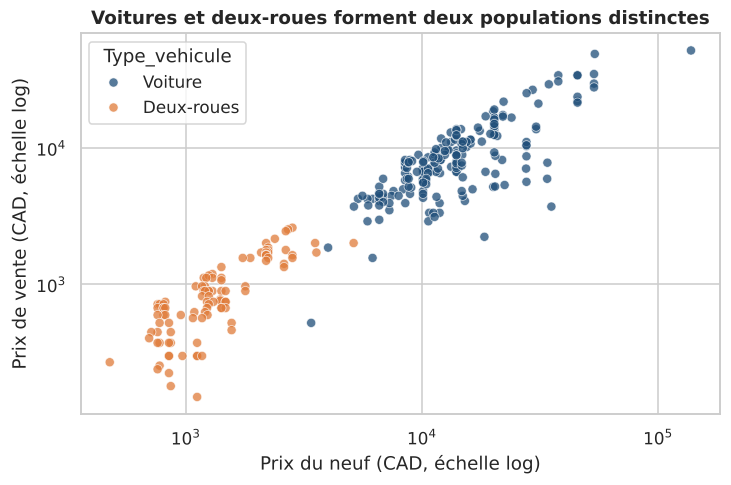

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=df_enrichi, x="Prix_neuf_CAD", y="Prix_vente_CAD", hue="Type_vehicule",
                palette=PALETTE[:2], alpha=.75, ax=ax)
ax.set(xscale="log", yscale="log", xlabel="Prix du neuf (CAD, échelle log)",
       ylabel="Prix de vente (CAD, échelle log)",
       title="Voitures et deux-roues forment deux populations distinctes")
sauver("01_voitures_vs_deux_roues")

## 1.4 Distribution de la variable cible

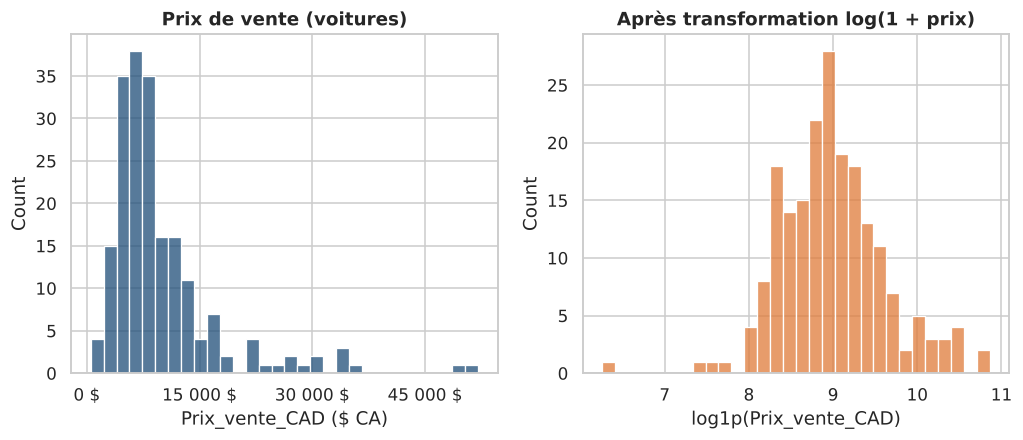

Asymétrie brute : 2.62 | après log : 0.05


In [10]:
voit = df_enrichi[df_enrichi.Type_vehicule == "Voiture"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(voit[CIBLE], bins=30, ax=axes[0], color=PALETTE[0])
axes[0].set(title="Prix de vente (voitures)", xlabel="Prix_vente_CAD ($ CA)"); axes[0].xaxis.set_major_formatter(CAD_FMT)
axes[0].xaxis.set_major_locator(plt.MaxNLocator(4))
sns.histplot(np.log1p(voit[CIBLE]), bins=30, ax=axes[1], color=PALETTE[1])
axes[1].set(title="Après transformation log(1 + prix)", xlabel="log1p(Prix_vente_CAD)")
sauver("02_distribution_cible")
print("Asymétrie brute :", round(voit[CIBLE].skew(), 2),
      "| après log :", round(np.log1p(voit[CIBLE]).skew(), 2))

La cible est fortement asymétrique à droite (quelques SUV haut de gamme). La transformation
logarithmique la rend presque symétrique : elle sera testée au Jalon 2.

## 1.5 Relations entre variables (voitures)

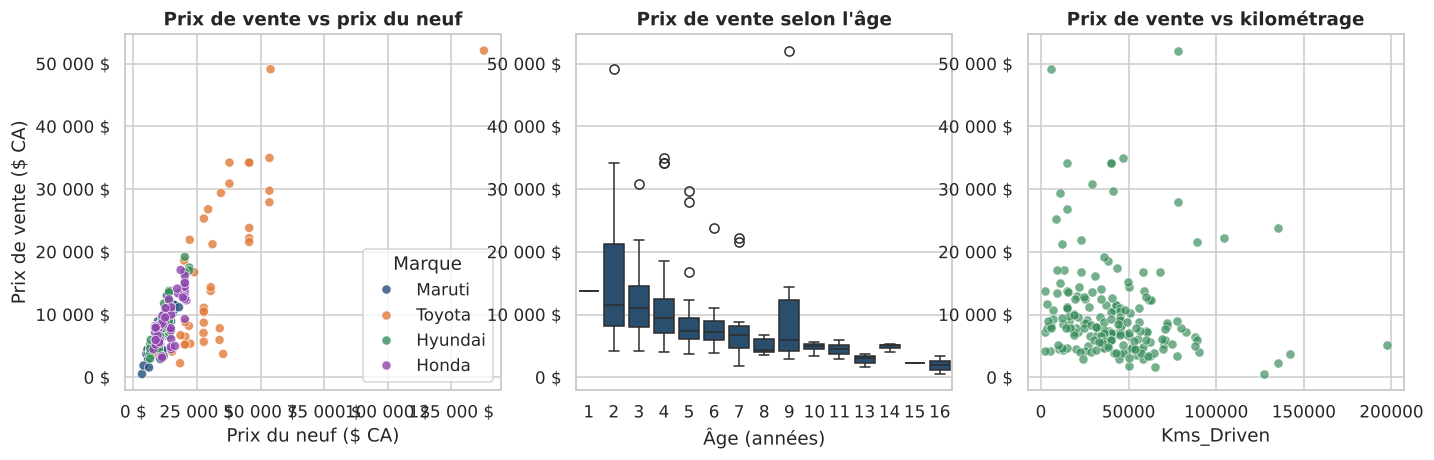

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.scatterplot(data=voit, x="Prix_neuf_CAD", y=CIBLE, hue="Marque", ax=axes[0], alpha=.8)
axes[0].set(title="Prix de vente vs prix du neuf", xlabel="Prix du neuf ($ CA)", ylabel="Prix de vente ($ CA)")
axes[0].xaxis.set_major_formatter(CAD_FMT)
for a in axes: a.yaxis.set_major_formatter(CAD_FMT)
sns.boxplot(data=voit, x="Age_vehicule", y=CIBLE, ax=axes[1], color=PALETTE[0])
axes[1].set(title="Prix de vente selon l'âge", xlabel="Âge (années)", ylabel="")
sns.scatterplot(data=voit, x="Kms_Driven", y=CIBLE, ax=axes[2], alpha=.7, color=PALETTE[2])
axes[2].set(title="Prix de vente vs kilométrage", xlabel="Kms_Driven", ylabel="")
sauver("03_relations_cible")

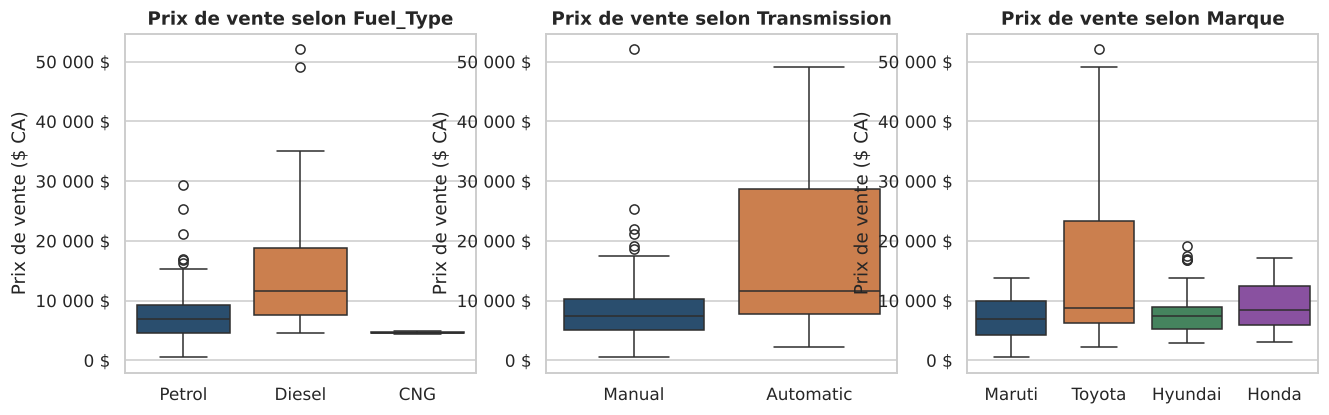

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Fuel_Type", "Transmission", "Marque"]):
    sns.boxplot(data=voit, x=c, y=CIBLE, ax=ax, palette=PALETTE)
    ax.set(title=f"Prix de vente selon {c}", ylabel="Prix de vente ($ CA)", xlabel="")
    ax.yaxis.set_major_formatter(CAD_FMT)
sauver("04_categories_cible")

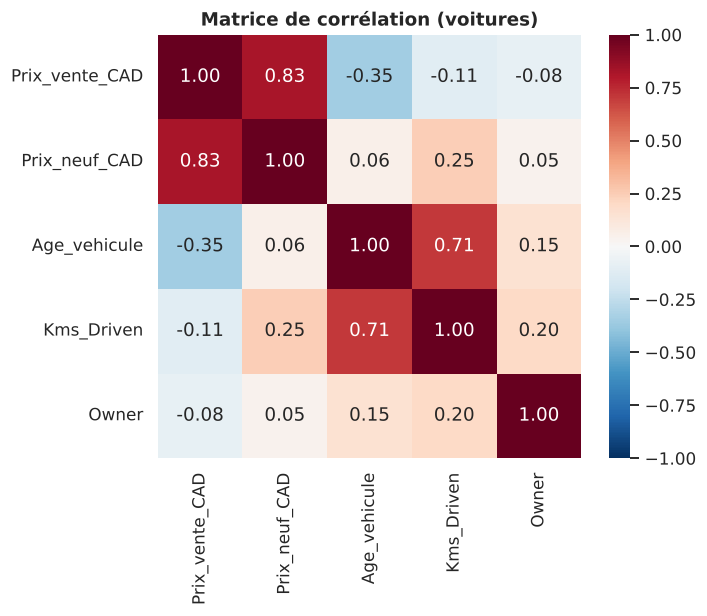

In [13]:
num = voit[["Prix_vente_CAD", "Prix_neuf_CAD", "Age_vehicule", "Kms_Driven", "Owner"]]
plt.figure(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Matrice de corrélation (voitures)")
sauver("05_correlations")

## 1.6 Principaux constats du Jalon 1
1. 301 lignes, 9 colonnes, **aucune valeur manquante**, **2 doublons exacts**.
2. **101 deux-roues** sont mêlés aux voitures → à exclure pour respecter le périmètre « voiture ».
3. `Car_Name` contient le modèle **sans la marque** (ex. *city*, *fortuner*) : la marque est
   reconstituée par table de correspondance (Maruti, Toyota, Hyundai, Honda).
4. `Year` est convertie en **âge** (`Age_vehicule = 2019 − Year`, 2019 = année de collecte).
5. Les prix sont convertis en **dollars canadiens** (1 lakh = 1 488 CAD).
6. `Prix_neuf_CAD` est la variable la plus corrélée à la cible ; l'âge et le kilométrage la font baisser.
7. Cible asymétrique → transformation logarithmique à tester.
8. Classes rares : CNG (2 voitures), Owner = 3 (1 seul cas).

---
# PARTIE 2 — JALON 2 : Préparation des données, séparation et premiers modèles
Objectifs du jalon (remise du 28 octobre 2026) :
1. terminer le prétraitement et la préparation des données ;
2. séparer les données en **entraînement / validation / test** ;
3. tester **au moins trois modèles de régression** (ici six) et comparer leurs performances
   pour choisir les métriques et les modèles à optimiser dans le contrat d'optimisation.

## 2.1 Préparation des données
Étapes : suppression des doublons → variables dérivées (marque, âge, prix en CAD) → exclusion des deux-roues →
traitement de la valeur extrême → sélection des variables.

In [14]:
df, journal = nettoyer(df_brut)
print(journal)

{'lignes_initiales': 301, 'doublons_supprimes': 2, 'deux_roues_exclus': 101, 'valeurs_manquantes': 0, 'lignes_finales': 198}


**Valeur extrême.** Une seule voiture (Toyota *Land Cruiser*, prix du neuf ≈ 137 800 CAD) dépasse
largement toutes les autres (maximum suivant : ≈ 53 900 CAD). Avec une seule observation, aucun modèle
ne peut apprendre ce segment de luxe ; elle est retirée et le domaine de validité du modèle est
documenté (prix du neuf ≤ 60 000 CAD).

In [15]:
display(df.nlargest(3, "Prix_neuf_CAD")[["Car_Name", "Year", "Prix_neuf_CAD", "Prix_vente_CAD"]])
SEUIL_PRIX_NEUF = 60_000  # CAD
n_avant = len(df)
df = df[df["Prix_neuf_CAD"] <= SEUIL_PRIX_NEUF].reset_index(drop=True)
journal["valeurs_extremes_retirees"] = n_avant - len(df)
journal["lignes_finales"] = len(df)
print("Jeu de données final :", df.shape)
RESULTATS["journal_nettoyage"] = journal

,Car_Name,Year,Prix_neuf_CAD,Prix_vente_CAD
85,land cruiser,2010,137789.0,52080.0
63,fortuner,2017,53910.0,49104.0
58,fortuner,2014,53508.0,29745.0


Jeu de données final : (197, 14)


## 2.2 Séparation entraînement / validation / test (60 / 20 / 20)
| Jeu | Rôle |
|---|---|
| **Entraînement** (60 %) | apprendre les paramètres des modèles et du prétraitement |
| **Validation** (20 %) | comparer les modèles et choisir ceux à optimiser |
| **Test** (20 %) | évaluation finale, utilisée **une seule fois** à la fin |

La séparation se fait en deux temps : on met d'abord 20 % de côté pour le test, puis on coupe le reste en
75 % entraînement / 25 % validation. La graine (`SEED = 42`) rend la séparation reproductible.

In [16]:
from sklearn.model_selection import train_test_split

FEATURES = VARIABLES_NUMERIQUES + VARIABLES_CATEGORIELLES
X, y = df[FEATURES], df[CIBLE]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=SEED)

repartition = pd.DataFrame({
    "lignes": [len(y_train), len(y_val), len(y_test)],
    "part (%)": [round(100 * len(s) / len(y)) for s in (y_train, y_val, y_test)],
    "prix moyen ($ CA)": [s.mean().round() for s in (y_train, y_val, y_test)],
    "prix médian ($ CA)": [s.median().round() for s in (y_train, y_val, y_test)],
}, index=["Entraînement", "Validation", "Test"])
RESULTATS["taille_train"], RESULTATS["taille_val"], RESULTATS["taille_test"] = len(X_train), len(X_val), len(X_test)
repartition

,lignes,part (%),prix moyen ($ CA),prix médian ($ CA)
Entraînement,117,59,9093.0,7738.0
Validation,40,20,11972.0,9598.0
Test,40,20,8772.0,7366.0


Les prix moyens et médians sont proches d'un jeu à l'autre : les trois jeux représentent bien la même population.

## 2.3 Prétraitement
**Prétraitement (dans un `Pipeline` scikit-learn, appris uniquement sur l'entraînement → pas de fuite de données)** :
- `Prix_neuf_CAD`, `Kms_Driven` : transformation `log1p` puis standardisation (distributions asymétriques) ;
- `Age_vehicule`, `Owner` : standardisation ;
- `Fuel_Type`, `Seller_Type`, `Transmission`, `Marque` : encodage *one-hot* (modalité inconnue ignorée).

In [17]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline

def creer_preprocesseur():
    log_scale = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())])
    return ColumnTransformer([
        ("log_num", log_scale, ["Prix_neuf_CAD", "Kms_Driven"]),
        ("num", StandardScaler(), ["Age_vehicule", "Owner"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), VARIABLES_CATEGORIELLES),
    ])

def cible_log(modele):
    """Le modèle apprend log(1+prix) ; les prédictions sont ramenées en dollars canadiens."""
    return TransformedTargetRegressor(regressor=modele, func=np.log1p, inverse_func=np.expm1)

def pipeline(modele):
    return Pipeline([("prep", creer_preprocesseur()), ("modele", modele)])

pipeline(cible_log(None)).named_steps["prep"].fit(X_train).get_feature_names_out()

array(['log_num__Prix_neuf_CAD', 'log_num__Kms_Driven',
       'num__Age_vehicule', 'num__Owner', 'cat__Fuel_Type_CNG',
       'cat__Fuel_Type_Diesel', 'cat__Fuel_Type_Petrol',
       'cat__Seller_Type_Individual', 'cat__Transmission_Manual',
       'cat__Marque_Honda', 'cat__Marque_Hyundai', 'cat__Marque_Maruti',
       'cat__Marque_Toyota'], dtype=object)

## 2.4 Modélisation — six modèles de régression comparés
| Modèle | Rôle |
|---|---|
| Régression linéaire (cible brute) | Référence (*baseline*) |
| Régression linéaire (cible log) | Effet de la transformation log |
| Ridge (cible log) | Linéaire régularisé |
| Forêt aléatoire (cible log) | Ensemble par *bagging*, non linéaire |
| Gradient Boosting (cible log) | Ensemble par *boosting* |
| XGBoost (cible log) | Boosting optimisé |

Chaque modèle est entraîné sur le jeu d'**entraînement** avec ses paramètres par défaut, puis évalué sur le jeu de
**validation**. Une validation croisée à 5 plis sur l'entraînement donne en plus la **stabilité** (écart-type de la MAE).

In [18]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

modeles_base = {
    "Régression linéaire (brute)": LinearRegression(),
    "Régression linéaire (log)": cible_log(LinearRegression()),
    "Ridge (log)": cible_log(Ridge(alpha=1.0)),
    "Forêt aléatoire (log)": cible_log(RandomForestRegressor(n_estimators=300, random_state=SEED)),
    "Gradient Boosting (log)": cible_log(GradientBoostingRegressor(random_state=SEED)),
    "XGBoost (log)": cible_log(XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=4,
                                            random_state=SEED, verbosity=0)),
}

def metriques(y_vrai, y_pred):
    return {"MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** .5,
            "R2": r2_score(y_vrai, y_pred),
            "MAPE_%": 100 * mean_absolute_percentage_error(y_vrai, y_pred)}

CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
lignes = {}
for nom, modele in modeles_base.items():
    pipe = pipeline(modele)
    t0 = time.time(); pipe.fit(X_train, y_train); duree = time.time() - t0
    res = metriques(y_val, pipe.predict(X_val))
    res["MAE_train"] = mean_absolute_error(y_train, pipe.predict(X_train))
    cv = -cross_val_score(pipeline(modele), X_train, y_train, cv=CV, scoring="neg_mean_absolute_error")
    res["MAE_CV"], res["MAE_CV_std"], res["entrainement_s"] = cv.mean(), cv.std(), duree
    lignes[nom] = res
base = pd.DataFrame(lignes).T.sort_values("MAE")
RESULTATS["comparaison_base_validation"] = base.round(4).to_dict(orient="index")
base.round(3)

,MAE,RMSE,R2,MAPE_%,MAE_train,MAE_CV,MAE_CV_std,entrainement_s
Ridge (log),1008.047,1548.665,0.965,10.806,975.521,1112.936,140.005,0.014
Régression linéaire (log),1047.054,1618.764,0.962,11.122,968.829,1117.314,140.740,0.010
Gradient Boosting (log),1465.324,2214.099,0.928,11.640,267.898,1309.989,288.169,0.043
XGBoost (log),1608.277,2557.464,0.904,12.185,31.196,1244.341,202.470,0.074
Forêt aléatoire (log),1613.424,2859.192,0.880,10.966,515.287,1481.430,322.456,0.276
Régression linéaire (brute),2132.579,3240.284,0.847,24.040,2144.568,2471.228,382.737,0.012


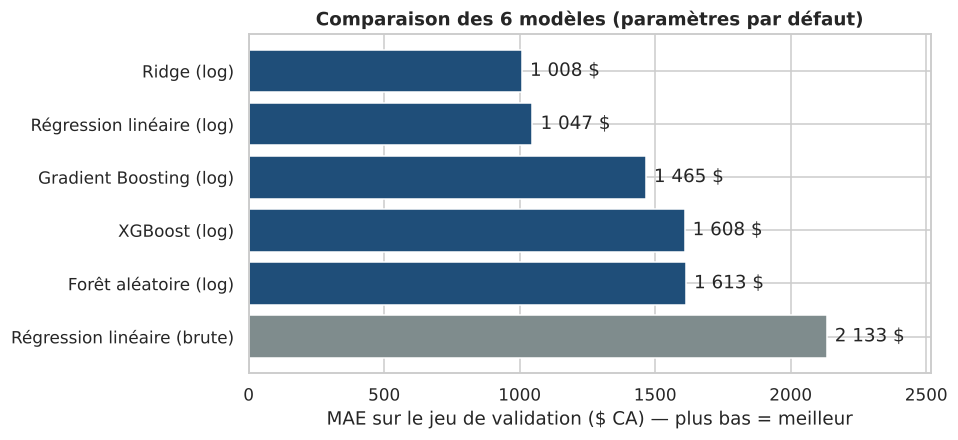

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
b = base.sort_values("MAE", ascending=False)
ax.barh(b.index, b["MAE"], color=[PALETTE[5] if "brute" in i else PALETTE[0] for i in b.index])
for i, v in enumerate(b["MAE"]): ax.text(v + 30, i, f"{v:,.0f} $".replace(",", " "), va="center")
ax.set(xlabel="MAE sur le jeu de validation ($ CA) — plus bas = meilleur",
       title="Comparaison des 6 modèles (paramètres par défaut)")
ax.set_xlim(0, b["MAE"].max() * 1.18)
sauver("06_comparaison_modeles_base")

### Lecture des résultats
1. **La transformation log de la cible est le levier le plus important** : la régression linéaire passe de
   2 133 $ à 1 047 $ de MAE sur la validation (erreur divisée par deux). La dépréciation d'une voiture est
   **multiplicative** (un pourcentage du prix par année), ce qu'un modèle linéaire capte mieux sur l'échelle log.
2. **Les modèles linéaires sur log sont les meilleurs et les plus stables** : Ridge (1 008 $) et régression linéaire
   (1 047 $), avec le plus faible écart-type en validation croisée (≈ 140 $).
3. **Les modèles à base d'arbres surapprennent** : XGBoost a une MAE de 31 $ sur l'entraînement contre 1 608 $ sur la
   validation (Gradient Boosting : 268 $ → 1 465 $). Avec seulement 117 voitures d'entraînement, ils mémorisent les données ;
   un réglage plus prudent (arbres moins profonds, taux d'apprentissage plus faible) devrait les améliorer.

## 2.5 Métriques retenues et objectifs pour le contrat d'optimisation
| Métrique | Pourquoi | Valeur actuelle (meilleur modèle, validation) | Objectif proposé |
|---|---|---|---|
| **MAE ($ CA)** — *principale* | erreur moyenne en dollars, facile à expliquer à un client | 1 008 $ (Ridge log) | **≤ 950 $** |
| MAPE (%) | erreur relative, juste pour les voitures bon marché comme pour les chères | 10,8 % | ≤ 10 % |
| RMSE ($ CA) | pénalise les grosses erreurs (SUV haut de gamme) | 1 549 $ | ≤ 1 500 $ |
| R² | part de la variance expliquée | 0,965 | ≥ 0,95 (à maintenir) |
| Écart MAE entraînement / validation | contrôle du surapprentissage | 1 577 $ (XGBoost) | ≤ 300 $ |

**Modèles retenus pour l'optimisation** : Ridge (log) (meilleur et plus simple), Gradient Boosting (log),
XGBoost (log) et Forêt aléatoire (log) (non linéaires, fort potentiel mais surapprentissage à corriger).
La régression linéaire brute reste la référence (*baseline*) à battre.

---
# PARTIE 2b — Premiers essais d'optimisation (préparation du contrat)
Recherche par grille (`GridSearchCV`, validation croisée 5 plis **sur l'entraînement seulement**, critère : MAE).
Le meilleur réglage de chaque modèle est ensuite mesuré sur le jeu de **validation** pour comparer avant / après.

In [20]:
from sklearn.model_selection import GridSearchCV

grilles = {
    "Ridge (log)": (cible_log(Ridge()),
        {"modele__regressor__alpha": [0.01, 0.1, 0.3, 1, 3, 10]}),
    "Forêt aléatoire (log)": (cible_log(RandomForestRegressor(random_state=SEED)),
        {"modele__regressor__n_estimators": [300],
         "modele__regressor__max_depth": [None, 8],
         "modele__regressor__min_samples_leaf": [1, 2, 4],
         "modele__regressor__max_features": [1.0, 0.6]}),
    "Gradient Boosting (log)": (cible_log(GradientBoostingRegressor(random_state=SEED)),
        {"modele__regressor__n_estimators": [200, 500],
         "modele__regressor__learning_rate": [0.03, 0.1],
         "modele__regressor__max_depth": [2, 3],
         "modele__regressor__subsample": [0.8, 1.0]}),
    "XGBoost (log)": (cible_log(XGBRegressor(random_state=SEED, verbosity=0)),
        {"modele__regressor__n_estimators": [300, 600],
         "modele__regressor__learning_rate": [0.03, 0.1],
         "modele__regressor__max_depth": [2, 3, 4],
         "modele__regressor__subsample": [0.8, 1.0]}),
}

recherches, lignes = {}, {}
for nom, (modele, grille) in grilles.items():
    t0 = time.time()
    gs = GridSearchCV(pipeline(modele), grille, cv=CV, scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    recherches[nom] = gs
    val = metriques(y_val, gs.best_estimator_.predict(X_val))
    lignes[nom] = {"MAE_val_avant": base.loc[nom, "MAE"], "MAE_val_apres": val["MAE"],
                   "RMSE_val": val["RMSE"], "R2_val": val["R2"], "MAPE_val_%": val["MAPE_%"],
                   "meilleurs_parametres": {k.replace("modele__regressor__", ""): v
                                            for k, v in gs.best_params_.items()},
                   "combinaisons": len(gs.cv_results_["params"]), "duree_s": round(time.time() - t0, 1)}
opt = pd.DataFrame(lignes).T.sort_values("MAE_val_apres")
opt

,MAE_val_avant,MAE_val_apres,RMSE_val,R2_val,MAPE_val_%,meilleurs_parametres,combinaisons,duree_s
Ridge (log),1008.046512,1008.046512,1548.664645,0.964941,10.80609,{'alpha': 1},6,1.5
Gradient Boosting (log),1465.324379,1271.337243,1788.274458,0.953252,10.790004,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",16,6.6
XGBoost (log),1608.277081,1537.118976,2387.858659,0.91665,12.059391,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",24,3.4
Forêt aléatoire (log),1613.423537,1585.606533,2802.756952,0.885168,10.923051,"{'max_depth': 8, 'max_features': 1.0, 'min_sam...",12,7.6


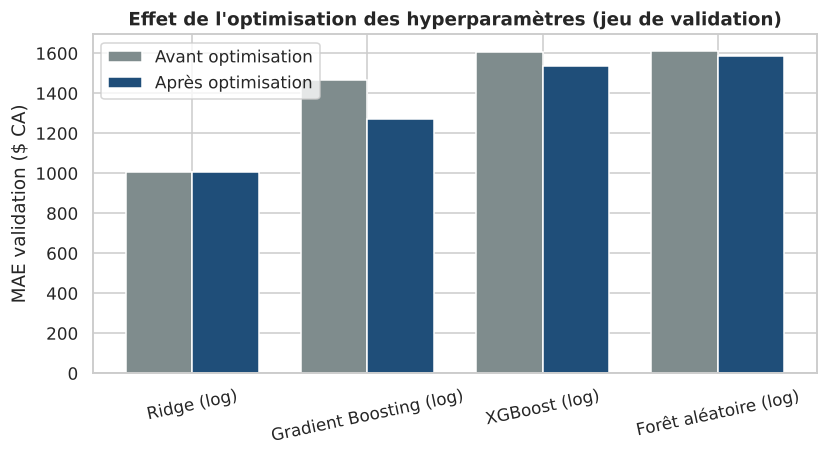

In [21]:
RESULTATS["optimisation"] = {k: {kk: (float(vv) if isinstance(vv, (float, np.floating)) else vv)
                                 for kk, vv in v.items()} for k, v in opt.to_dict(orient="index").items()}
x = np.arange(len(opt)); w = .38
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(x - w/2, opt["MAE_val_avant"].astype(float), w, label="Avant optimisation", color=PALETTE[5])
ax.bar(x + w/2, opt["MAE_val_apres"].astype(float), w, label="Après optimisation", color=PALETTE[0])
ax.set_xticks(x, opt.index, rotation=12); ax.set_ylabel("MAE validation ($ CA)")
ax.set_title("Effet de l'optimisation des hyperparamètres (jeu de validation)"); ax.legend()
sauver("07_gain_optimisation")

### Choix du modèle final
Critère principal : **MAE sur le jeu de validation**. Si deux modèles sont quasi à égalité
(écart < 30 $ CA), on privilégie le plus simple et le plus interprétable.

In [22]:
classement = opt[["MAE_val_apres", "RMSE_val", "R2_val", "MAPE_val_%"]].astype(float)
classement.columns = ["MAE", "RMSE", "R2", "MAPE_%"]
classement.loc["Régression linéaire (log)"] = base.loc["Régression linéaire (log)", ["MAE", "RMSE", "R2", "MAPE_%"]].astype(float)
classement = classement.sort_values("MAE")
simplicite = ["Régression linéaire (log)", "Ridge (log)", "Forêt aléatoire (log)",
              "Gradient Boosting (log)", "XGBoost (log)"]
meilleur_mae = classement["MAE"].min()
proches = [m for m in simplicite if classement.loc[m, "MAE"] <= meilleur_mae + 30]
NOM_FINAL = proches[0]
print("Classement sur la validation :\n", classement.round(3))
print("\nModèles à moins de 30 $ du meilleur :", proches)
print("➡ Modèle final retenu :", NOM_FINAL)
RESULTATS["modele_final"] = NOM_FINAL
RESULTATS["classement_validation"] = classement.round(4).to_dict(orient="index")

Classement sur la validation :
                                 MAE      RMSE     R2  MAPE_%
Ridge (log)                1008.047  1548.665  0.965  10.806
Régression linéaire (log)  1047.054  1618.764  0.962  11.122
Gradient Boosting (log)    1271.337  1788.274  0.953  10.790
XGBoost (log)              1537.119  2387.859  0.917  12.059
Forêt aléatoire (log)      1585.607  2802.757  0.885  10.923

Modèles à moins de 30 $ du meilleur : ['Ridge (log)']
➡ Modèle final retenu : Ridge (log)


## 2b.2 Évaluation finale sur le jeu de test (jamais vu jusqu'ici)
Les modèles sont réentraînés sur **entraînement + validation** (157 voitures), puis évalués **une seule fois** sur le test.

In [23]:
X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
candidats = {"Régression linéaire (brute)": pipeline(LinearRegression()),
             "Régression linéaire (log)": pipeline(cible_log(LinearRegression()))}
candidats.update({n: gs.best_estimator_ for n, gs in recherches.items()})

test_res, preds = {}, {}
for n, p in candidats.items():
    p.fit(X_trval, y_trval); preds[n] = p.predict(X_test)
    test_res[n] = metriques(y_test, preds[n])
test_df = pd.DataFrame(test_res).T.sort_values("MAE")
RESULTATS["evaluation_test"] = test_df.round(4).to_dict(orient="index")
test_df.round(3)

,MAE,RMSE,R2,MAPE_%
Forêt aléatoire (log),1012.146,1378.530,0.935,14.362
Régression linéaire (log),1104.846,1385.637,0.935,14.635
Ridge (log),1112.003,1395.984,0.934,14.727
XGBoost (log),1170.870,1698.681,0.902,14.019
Gradient Boosting (log),1287.707,1872.509,0.881,15.264
Régression linéaire (brute),1946.775,2362.885,0.810,28.950


**Lecture.** Sur le test, la forêt aléatoire obtient la plus faible MAE (1 012 $) alors qu'elle était dernière sur la
validation : avec 40 voitures par jeu, l'écart entre modèles (≈ 100 $) reste dans la marge de variation. Ridge et la
régression linéaire (log) donnent des résultats très proches et stables sur la validation, la validation croisée et le test ;
c'est pourquoi le modèle le plus simple est conservé.

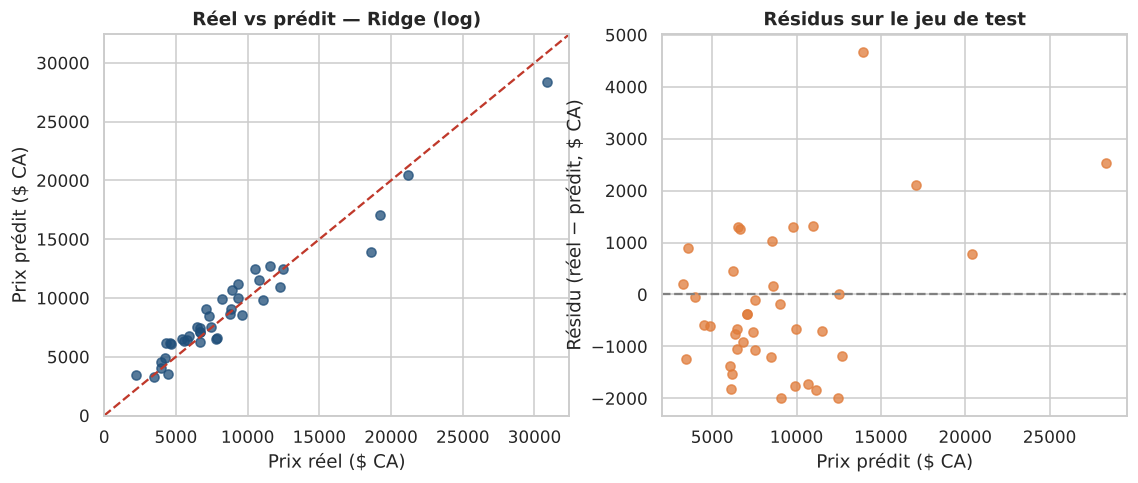

In [24]:
modele_final = candidats[NOM_FINAL]
y_pred = preds[NOM_FINAL]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, y_pred, alpha=.75, color=PALETTE[0])
lim = [0, max(y_test.max(), y_pred.max()) * 1.05]
axes[0].plot(lim, lim, "--", color=PALETTE[4]); axes[0].set(xlim=lim, ylim=lim)
axes[0].set(xlabel="Prix réel ($ CA)", ylabel="Prix prédit ($ CA)", title=f"Réel vs prédit — {NOM_FINAL}")
residus = y_test - y_pred
axes[1].scatter(y_pred, residus, alpha=.75, color=PALETTE[1]); axes[1].axhline(0, ls="--", color="grey")
axes[1].set(xlabel="Prix prédit ($ CA)", ylabel="Résidu (réel − prédit, $ CA)", title="Résidus sur le jeu de test")
sauver("08_reel_vs_predit_residus")

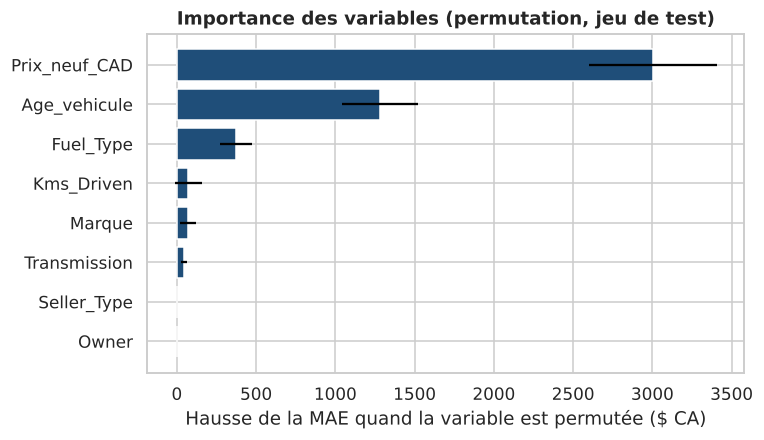

Prix_neuf_CAD    3003.220
Age_vehicule     1279.178
Fuel_Type         371.714
Kms_Driven         73.459
Marque             71.208
Transmission       44.071
Owner               0.000
Seller_Type         0.000
dtype: float64

In [25]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(modele_final, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=30, random_state=SEED)
imp_df = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_df.index, imp_df.values, xerr=imp.importances_std[np.argsort(imp.importances_mean)], color=PALETTE[0])
ax.set(xlabel="Hausse de la MAE quand la variable est permutée ($ CA)",
       title="Importance des variables (permutation, jeu de test)")
sauver("09_importance_variables")
RESULTATS["importance_variables"] = imp_df.sort_values(ascending=False).round(4).to_dict()
imp_df.sort_values(ascending=False).round(3)

In [26]:
# Interprétation : coefficients de la régression linéaire (log), modèle de référence interprétable
lin = candidats["Régression linéaire (log)"]
reg = lin.named_steps["modele"].regressor_
noms = lin.named_steps["prep"].get_feature_names_out()
coef = pd.Series(reg.coef_, index=noms)
effet = (np.exp(coef) - 1) * 100
coef_df = pd.DataFrame({"coefficient (log)": coef.round(3), "effet sur le prix (%)": effet.round(1)}).sort_values("coefficient (log)")
RESULTATS["coefficients_lineaire"] = coef_df["effet sur le prix (%)"].to_dict()
display(coef_df)
print("Note : les variables numériques sont standardisées → effet pour +1 écart-type.")

,coefficient (log),effet sur le prix (%)
num__Age_vehicule,-0.312,-26.8
cat__Fuel_Type_CNG,-0.117,-11.1
cat__Transmission_Manual,-0.060,-5.8
log_num__Kms_Driven,-0.052,-5.1
num__Owner,-0.046,-4.5
cat__Marque_Toyota,-0.038,-3.7
cat__Marque_Maruti,-0.029,-2.9
cat__Fuel_Type_Petrol,-0.021,-2.1
cat__Seller_Type_Individual,-0.020,-2.0
cat__Marque_Honda,0.005,0.5


Note : les variables numériques sont standardisées → effet pour +1 écart-type.


In [27]:
# Erreur par segment de prix : où le modèle se trompe-t-il le plus ?
seg = pd.cut(y_test, bins=[0, 5000, 10000, 15000, 60000], labels=["< 5 000 $", "5 000–10 000 $", "10 000–15 000 $", "> 15 000 $"])
par_seg = pd.DataFrame({"segment": seg, "err_abs": np.abs(residus),
                        "err_rel_%": 100 * np.abs(residus) / y_test}).groupby("segment", observed=True) \
            .agg(n=("err_abs", "size"), MAE=("err_abs", "mean"), erreur_relative_moy=("err_rel_%", "mean"))
RESULTATS["erreur_par_segment"] = par_seg.round(3).reset_index().astype({"segment": str}).to_dict(orient="records")
par_seg.round(2)

,n,MAE,erreur_relative_moy
segment,,,
< 5 000 $,9,925.04,24.11
5 000–10 000 $,21,932.54,12.67
10 000–15 000 $,6,1081.86,9.70
> 15 000 $,4,2520.06,11.98


---
# PARTIE 3 — JALON 3 : Solution finale, déploiement, suivi
## 3.1 Intervalle de prédiction (marge d'erreur)
Le cahier des charges exige une estimation **accompagnée d'une marge d'erreur**.
Méthode : **prédiction conforme (*split conformal*)** sur l'échelle log.
1. Prédictions hors-pli (validation croisée) sur l'entraînement ;
2. quantile 80 % des erreurs absolues en log → `q` ;
3. intervalle : `[ŷ·e^(−q), ŷ·e^(+q)]` (marge en pourcentage, adaptée à la dépréciation multiplicative).
On vérifie ensuite la couverture réelle sur le test.

In [28]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
oof = cross_val_predict(clone(modele_final), X_trval, y_trval, cv=CV)
err_log = np.abs(np.log1p(y_trval) - np.log1p(oof))
NIVEAU = 0.80
n = len(err_log)
q = float(np.quantile(err_log, min(1, np.ceil((n + 1) * NIVEAU) / n)))
bas = np.expm1(np.log1p(y_pred) - q); haut = np.expm1(np.log1p(y_pred) + q)
couverture = float(np.mean((y_test >= bas) & (y_test <= haut)))
print(f"q = {q:.3f} → intervalle ≈ −{100*(1-np.exp(-q)):.0f} % / +{100*(np.exp(q)-1):.0f} % autour de la prédiction")
print(f"Couverture observée sur le test : {couverture:.0%} (cible {NIVEAU:.0%})")
RESULTATS["intervalle"] = {"niveau": NIVEAU, "q_log": q, "couverture_test": couverture,
                           "marge_basse_pct": 100*(1-np.exp(-q)), "marge_haute_pct": 100*(np.exp(q)-1)}

q = 0.217 → intervalle ≈ −20 % / +24 % autour de la prédiction
Couverture observée sur le test : 82% (cible 80%)


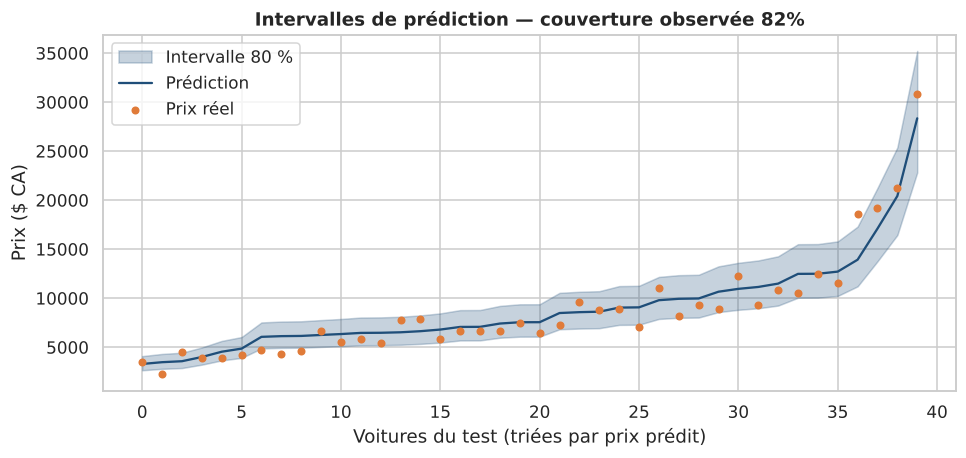

In [29]:
ordre = np.argsort(y_pred)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.fill_between(range(len(ordre)), bas[ordre], haut[ordre], alpha=.25, color=PALETTE[0], label="Intervalle 80 %")
ax.plot(range(len(ordre)), y_pred[ordre], color=PALETTE[0], label="Prédiction")
ax.scatter(range(len(ordre)), np.array(y_test)[ordre], color=PALETTE[1], s=18, zorder=3, label="Prix réel")
ax.set(xlabel="Voitures du test (triées par prix prédit)", ylabel="Prix ($ CA)",
       title=f"Intervalles de prédiction — couverture observée {couverture:.0%}")
ax.legend(); sauver("10_intervalles_prediction")

## 3.2 Entraînement du modèle final sur toutes les données et export

In [30]:
modele_deploye = clone(modele_final).fit(X, y)
domaine = {
    "Prix_neuf_CAD": [float(X.Prix_neuf_CAD.min()), float(X.Prix_neuf_CAD.max())],
    "Age_vehicule": [int(X.Age_vehicule.min()), int(X.Age_vehicule.max())],
    "Kms_Driven": [int(X.Kms_Driven.min()), int(X.Kms_Driven.max())],
    "Year": [int(df.Year.min()), int(df.Year.max())],
    "Fuel_Type": sorted(X.Fuel_Type.unique()), "Seller_Type": sorted(X.Seller_Type.unique()),
    "Transmission": sorted(X.Transmission.unique()), "Marque": sorted(X.Marque.unique()),
}
paquet = {"modele": modele_deploye, "nom": NOM_FINAL, "q_log": q, "niveau": NIVEAU,
          "features": FEATURES, "annee_reference": ANNEE_REFERENCE, "domaine": domaine,
          "devise": "CAD", "taux_inr_cad": TAUX_INR_CAD, "date_taux": DATE_TAUX,
          "metriques_test": RESULTATS["evaluation_test"][NOM_FINAL],
          "version": "1.0.0", "date_entrainement": time.strftime("%Y-%m-%d")}
(RACINE / "models").mkdir(exist_ok=True)
joblib.dump(paquet, RACINE / "models" / "modele_final.joblib")
df.to_csv(RACINE / "data" / "car_data_nettoye.csv", index=False)
RESULTATS["domaine_validite"] = domaine
print("Modèle exporté :", RACINE / "models" / "modele_final.joblib")

Modèle exporté : /home/claude/run/models/modele_final.joblib


## 3.3 Test du prototype : prédiction et temps de réponse

In [31]:
p = joblib.load(RACINE / "models" / "modele_final.joblib")
exemple = preparer_entree(annee=2015, prix_neuf_cad=14_700, kms=40000, carburant="Petrol",
                          vendeur="Dealer", transmission="Manual", proprietaires=0, marque_="Honda")
t0 = time.perf_counter()
for _ in range(200): pred = float(p["modele"].predict(exemple)[0])
temps_ms = (time.perf_counter() - t0) / 200 * 1000
bas_, haut_ = np.expm1(np.log1p(pred) - p["q_log"]), np.expm1(np.log1p(pred) + p["q_log"])
print(f"Honda City 2015, 40 000 km : {pred:,.0f} $ CA (intervalle 80 % : {bas_:,.0f} – {haut_:,.0f} $)".replace(",", " "))
print(f"Temps de réponse moyen : {temps_ms:.1f} ms par prédiction")
RESULTATS["temps_reponse_ms"] = temps_ms
RESULTATS["exemple_prediction"] = {"entree": "Honda City 2015, essence, manuelle, 40 000 km, concessionnaire, prix neuf 14 700 $ CA",
                                   "prediction": pred, "bas": float(bas_), "haut": float(haut_)}

Honda City 2015  40 000 km : 9 362 $ CA (intervalle 80 % : 7 536 – 11 632 $)
Temps de réponse moyen : 5.3 ms par prédiction


## 3.4 Suivi : référence pour la détection de dérive
Les statistiques de référence (distribution des variables d'entrée) sont sauvegardées pour être comparées
aux nouvelles annonces avec l'indice PSI (*Population Stability Index*) — voir `src/suivi.py`.

In [32]:
reference = {}
for c in VARIABLES_NUMERIQUES:
    bornes = np.unique(np.quantile(X[c], np.linspace(0, 1, 11)))
    bornes[0], bornes[-1] = -np.inf, np.inf
    props = np.histogram(X[c], bins=bornes)[0] / len(X)
    reference[c] = {"bornes": [None if np.isinf(b) else float(b) for b in bornes], "proportions": props.round(4).tolist()}
reference.update({c: {"frequences": X[c].value_counts(normalize=True).round(4).to_dict()} for c in VARIABLES_CATEGORIELLES})
reference["mae_reference"] = RESULTATS["evaluation_test"][NOM_FINAL]["MAE"]
with open(RACINE / "models" / "reference_suivi.json", "w", encoding="utf-8") as f:
    json.dump(reference, f, ensure_ascii=False, indent=2)

def convertir(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, dict): return {str(k): convertir(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [convertir(v) for v in o]
    return o
with open(RACINE / "reports" / "resultats.json", "w", encoding="utf-8") as f:
    json.dump(convertir(RESULTATS), f, ensure_ascii=False, indent=2)
print("Résultats sauvegardés dans reports/resultats.json")

Résultats sauvegardés dans reports/resultats.json


## 3.5 Conclusion
- Tous les prix sont exprimés en **dollars canadiens** (taux Banque du Canada du 21/10/2026, 1 lakh = 1 488 CAD).
- Le jeu CarDekho a été nettoyé (doublons, 101 deux-roues hors périmètre, 1 valeur extrême) → **197 voitures**.
- Les données sont séparées en entraînement (60 %), validation (20 %) et test (20 %).
- Six modèles ont été comparés sur la validation ; la **transformation logarithmique** de la cible est le levier le plus important.
- Le modèle final, ses métriques, l'intervalle de prédiction et le temps de réponse sont reportés ci-dessus
  et dans le cahier des charges.
- Le prototype (`app/app.py`, Streamlit) charge `models/modele_final.joblib` et renvoie une estimation
  avec sa marge d'erreur ; `src/suivi.py` contrôle la dérive des données en production.